# Chapter 25 | Worked solutions

*Speech and Audio*

These eleven solutions move from samples and windows to transcript errors and live captions. Each answer explains the reasoning before checking it with small, deterministic examples. The figures show overlapping frames, tone frequencies and a changing caption.

The examples use synthetic waveforms and supplied transcript histories. They illustrate calculations and evaluation protocols; they do not measure a trained speech recognizer.

Open this notebook inside `transformers-book`, select a Python kernel with NumPy and Matplotlib, and run all cells in order. Everything runs on CPU without downloading a model or dataset. The written PDF contains all explanations and plots; the notebook PDF adds code and recorded outputs.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch25_speech_audio"
    )
    if model_path.is_dir():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
from examples.ch25_speech_audio.model import word_error_rate
plt.rcParams.update({"font.size": 11, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Count complete frames

Number the 24 samples from 0 to 23. An eight-sample frame starting at $s$ ends at $s+7$, so the last possible start is 16. Advance by the hop until a complete frame would no longer fit.

| Hop | Starts | Inclusive sample ranges | Shared samples per adjacent pair |
| --- | --- | --- | --- |
| 4 | 0, 4, 8, 12, 16 | 0–7; 4–11; 8–15; 12–19; 16–23 | 4 |
| 8 | 0, 8, 16 | 0–7; 8–15; 16–23 | 0 |

The number of complete unpadded frames is $\max(0,1+\lfloor(L-N)/H\rfloor)$. For these settings it is five or three. In the plot, each horizontal segment covers eight sample intervals. Dashed lines are boundaries between sample intervals, so the endpoint of the last segment is 24 even though the last sample index is 23.

Hop 4: starts [0, 4, 8, 12, 16], overlap 4
Hop 8: starts [0, 8, 16], overlap 0


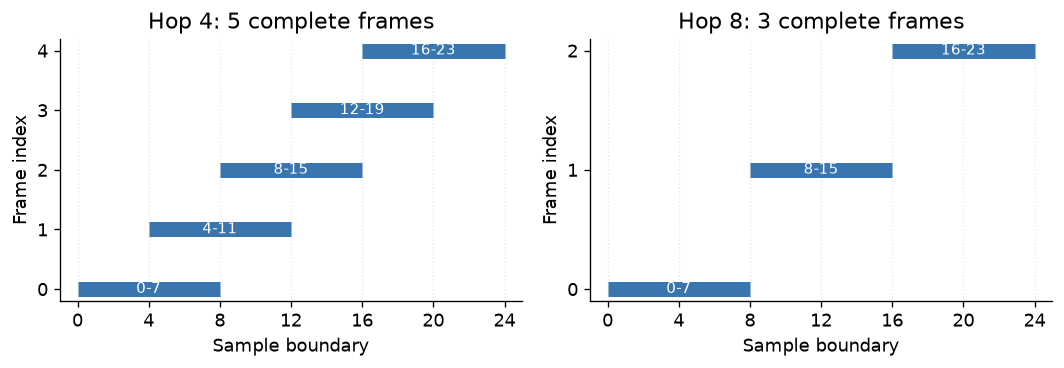

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True)
for ax, hop, expected in zip(axes, (4, 8), (5, 3)):
    starts = np.arange(0, 24 - 8 + 1, hop)
    assert len(starts) == expected
    for row, start in enumerate(starts):
        ax.plot([start, start + 8], [row, row], lw=9,
                solid_capstyle="butt", color="#3976af")
        ax.text(start + 4, row, f"{start}-{start + 7}",
                ha="center", va="center", color="white", fontsize=9)
    ax.set(yticks=range(expected), ylabel="Frame index", xlabel="Sample boundary",
           title=f"Hop {hop}: {len(starts)} complete frames", xlim=(-1, 25))
    ax.set_xticks(range(0, 25, 4)); ax.grid(axis="x", ls=":", alpha=.3)
    print(f"Hop {hop}: starts {starts.tolist()}, overlap {8-hop}")
fig.tight_layout(); display(fig); plt.close(fig)

## 2. Read the axes

A bin checks an integer number of cycles in one frame. At $f_s=8{,}000$ Hz and $N=16$, the frame spans 2 ms. One cycle per frame is therefore 500 cycles per second. Bins 0, 1 and 8 represent 0, 500 and 4,000 Hz. The hop of eight samples separates starts by 1 ms.

| Configuration | Window duration | Bin spacing $f_s/N$ | Start spacing $H/f_s$ |
| --- | --- | --- | --- |
| $N=16,H=8$ | 2 ms | 500 Hz | 1 ms |
| Change only $N$ to 32 | 4 ms | 250 Hz | 1 ms |
| Restore $N=16$; change only $H$ to 4 | 2 ms | 500 Hz | 0.5 ms |

Longer windows put bins closer together while combining a longer interval. Smaller hops add more overlapping measurements; each window still spans the same interval. Bin spacing and the ability to distinguish nearby tones are related but not identical. Simply relabeling the sample rate is not resampling the waveform.

In [3]:
for frame_length, hop in [(16, 8), (32, 8), (16, 4)]:
    frequency_spacing = 8000 / frame_length
    window_ms = 1000 * frame_length / 8000
    hop_ms = 1000 * hop / 8000
    print(f"N={frame_length}, H={hop}: window={window_ms:g} ms, "
          f"bins={frequency_spacing:g} Hz, starts={hop_ms:g} ms")
np.testing.assert_array_equal(np.fft.rfftfreq(16, 1/8000)[[0,1,8]],
                              [0, 500, 4000])

N=16, H=8: window=2 ms, bins=500 Hz, starts=1 ms
N=32, H=8: window=4 ms, bins=250 Hz, starts=1 ms
N=16, H=4: window=2 ms, bins=500 Hz, starts=0.5 ms


## 3. Choose a decoding task

The spoken language is Spanish in both requests. In the original multilingual Whisper interface, the task specifies whether to transcribe that speech or translate it into English.

| Request | Spoken language | Task | Example output |
| --- | --- | --- | --- |
| Spanish transcript | Spanish (`es`) | `transcribe` | Buenos días |
| English translation | Spanish (`es`) | `translate` | Good morning |

Both requests supply the same recording and preprocessing, so the audio encoder receives the same log-Mel features. The decoder task token changes the requested output. Selecting English as the spoken language would misdescribe this recording. This original translation task does not mean translation into an arbitrary target language.

The following table is a supplied teaching fixture, not a model call. Compare a transcript with a transcript in the spoken language; use an appropriate translation reference when evaluating the translation task.

In [4]:
requests = [
    {"language": "es", "task": "transcribe", "example": "Buenos días"},
    {"language": "es", "task": "translate", "example": "Good morning"},
]
assert {r["language"] for r in requests} == {"es"}
for request in requests:
    print(request["language"], request["task"], "->", request["example"])

es transcribe -> Buenos días
es translate -> Good morning


## 4. Align the words

Keep the agreeing words in order, substitute *red* for *blue*, and insert *now* at the end.

| Reference | Hypothesis | Operation |
| --- | --- | --- |
| turn | turn | Match |
| at | at | Match |
| the | the | Match |
| blue | red | Substitute |
| door | door | Match |
| gap | now | Insert |

The sentences differ in length by one. A single-edit solution would therefore have to be an insertion, but that would preserve *blue*, which is absent from the hypothesis. At least two edits are needed, and the displayed alignment achieves two. Thus $(S,D,I)=(1,0,1)$ and WER is $2/5=40\%$.

Reversing the sentences reverses the insertion into a deletion. Each unit-cost edit can be undone with one edit, so the minimum distance stays two. The six-word reference now gives $2/6=1/3\approx33.3\%$. WER is asymmetric because it uses reference length, not because the unit-cost edit distance is asymmetric.

In [5]:
reference = "turn at the blue door".split()
hypothesis = "turn at the red door now".split()
forward = word_error_rate(reference, hypothesis)
reverse = word_error_rate(hypothesis, reference)
assert (forward["substitutions"], forward["deletions"], forward["insertions"]) == (1, 0, 1)
assert (reverse["substitutions"], reverse["deletions"], reverse["insertions"]) == (1, 1, 0)
assert forward["edits"] == reverse["edits"] == 2
print(f"Forward: 2/5 = {forward['wer']:.2%}")
print(f"Reverse: 2/6 = {reverse['wer']:.2%}")

Forward: 2/5 = 40.00%
Reverse: 2/6 = 33.33%


## 5. Check the spectrogram shape

The 16 zero samples have indices 0 through 15. An eight-sample
frame starting at index $s$ needs the samples through $s+7$.
Stepping by four gives three complete frames, covering indices
0–7, 4–11, and 8–15. A fourth frame starting at 12 would need
samples through index 19, so the function drops it.

Each row of the power array corresponds to a frame start. Divide
its start index by $f_s=8{,}000$ samples per second to get
$[0, 0.0005, 0.001]$ seconds, or $[0, 0.5, 1]$ milliseconds.
Each column corresponds to a frequency bin. With $N=8$ samples
per frame, the spacing is $f_s/N=1{,}000$ Hz. The real FFT
keeps bins 0 through 4, from 0 Hz (the constant component) to
4,000 Hz (half the sample rate). Three starts and five frequencies
give a power array of shape $(3,5)$.

The Hann window multiplies each sample by a weight. All the
samples remain zero, so every Fourier coefficient is zero.
The function returns raw squared Fourier magnitudes, and all
$3\times 5=15$ entries are exactly zero.

In [6]:
from examples.ch25_speech_audio.model import frame_power_spectrogram

start_seconds, bin_hz, power = frame_power_spectrogram(
    np.zeros(16), sample_rate=8000, frame_length=8, hop_length=4
)

np.testing.assert_array_equal(start_seconds, [0, 0.0005, 0.001])
np.testing.assert_array_equal(bin_hz, [0, 1000, 2000, 3000, 4000])
np.testing.assert_array_equal(power, np.zeros((3, 5)))

print("Frame starts (s)", start_seconds)
print("Frame starts (ms)", start_seconds * 1000)
print("Bin frequencies (Hz)", bin_hz)
print("Power shape", power.shape)
print(power)

Frame starts (s) [0.     0.0005 0.001 ]
Frame starts (ms) [0.  0.5 1. ]
Bin frequencies (Hz) [   0. 1000. 2000. 3000. 4000.]
Power shape (3, 5)
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]


## 6. Find a tone

At 8,000 samples per second, a 1,000 Hz sine repeats every eight
samples, so a 16-sample frame contains two cycles. A 2,000 Hz sine
repeats every four samples, giving four cycles per frame. With a
hop of eight, the complete frames cover indices 0–15, 8–23, and
16–31. Their starts are 0, 1, and 2 milliseconds. Each hop is a
whole number of cycles for both tones, so a tone begins at the
same phase in all three frames.

Bin $k$ measures $k$ cycles per frame. The spacing is
$8{,}000/16=500$ Hz, so the bins run from 0 to 4,000 Hz in 500 Hz
steps. We expect the 1,000 Hz tone to peak in bin 2 and the
2,000 Hz tone to peak in bin 4.

The function tapers each frame with the symmetric Hann window.
For a local sample index $n$ from 0 through 15, the weight is
$w[n]=(1-\cos(2\pi n/15))/2$. The cosine makes one full turn
between indices 0 and 15, giving both end samples zero weight.
A real sine has a positive
and a negative frequency component. When the Fourier transform
tests the matching positive bin, the phase of the positive
component cancels against the phase of that bin's Fourier
wave. Its contributions therefore add in proportion to the sum
of the window weights. The taper also spreads energy into
neighboring bins. To see which bin wins after tapering, we
check all nine squared magnitudes against the direct Fourier sum
with the same weights.

In [7]:
from examples.ch25_speech_audio.model import frame_power_spectrogram

sample_rate = 8000
frame_length = 16
hop_length = 8
sample_indices = np.arange(32)
starts = [0, 8, 16]
offsets = np.arange(frame_length)
bins = np.arange(9)

# Write out the weights and Fourier waves for the direct sum.
window = 0.5 - 0.5 * np.cos(
    2 * np.pi * offsets / (frame_length - 1)
)
angles = -2j * np.pi * np.outer(bins, offsets) / frame_length
fourier_waves = np.exp(angles)

for tone_hz, expected_bin in [(1000, 2), (2000, 4)]:
    phase = 2 * np.pi * tone_hz * sample_indices / sample_rate
    waveform = np.sin(phase)
    start_seconds, bin_hz, power = frame_power_spectrogram(
        waveform, sample_rate, frame_length, hop_length
    )

    frames = np.stack(
        [waveform[start:start + frame_length] for start in starts]
    )
    direct_power = np.abs((frames * window) @ fourier_waves.T) ** 2
    np.testing.assert_array_equal(start_seconds, [0, 0.001, 0.002])
    np.testing.assert_array_equal(bin_hz, 500 * bins)
    np.testing.assert_allclose(
        power, direct_power, rtol=1e-12, atol=1e-12
    )

    peak_bins = power.argmax(axis=1)
    np.testing.assert_array_equal(peak_bins, [expected_bin] * 3)
    np.testing.assert_array_equal(bin_hz[peak_bins], [tone_hz] * 3)

    ranked_power = np.sort(power, axis=1)
    print(f"{tone_hz} Hz tone")
    print("  Peak bins by frame", peak_bins)
    print("  Peak frequencies (Hz)", bin_hz[peak_bins])
    print(f"  First frame peak power {ranked_power[0, -1]:.6f}")
    print(f"  First frame next-highest {ranked_power[0, -2]:.6f}")

1000 Hz tone
  Peak bins by frame [2 2 2]
  Peak frequencies (Hz) [1000. 1000. 1000.]
  First frame peak power 13.974058
  First frame next-highest 4.307203
2000 Hz tone
  Peak bins by frame [4 4 4]
  Peak frequencies (Hz) [2000. 2000. 2000.]
  First frame peak power 14.062500
  First frame next-highest 4.207856


Using `argmax(axis=1)` picks one bin from each frame row. The
peak bin is 2 in all three rows for the first tone and 4 in all
three rows for the second. The first-frame comparison shows how
much higher the matching bin is than the next-highest bin. The
same sample pattern, with the same taper, gives the other two
frames the same spectrum up to floating-point roundoff.

The peak appears at 1,000 or 2,000 Hz in every frame. Neighboring bins are nonzero because the finite Hann window spreads the spectrum. The plot normalizes each tone to its own peak to compare shape; it does not compare absolute amplitude.

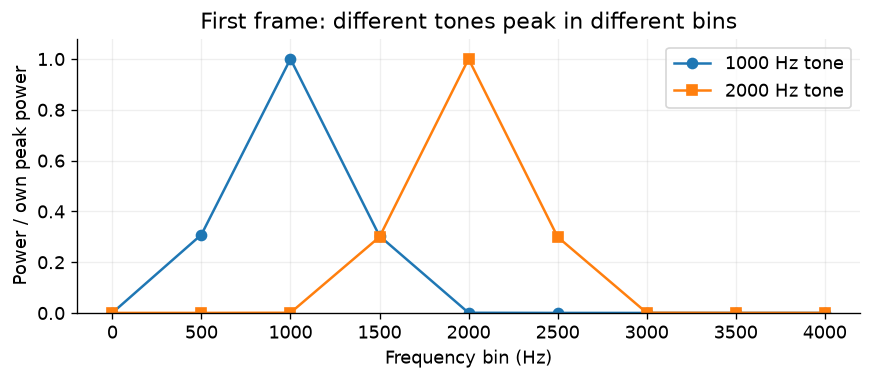

In [8]:
fig, ax = plt.subplots(figsize=(7.4, 3.3))
for tone_hz, marker in [(1000, "o"), (2000, "s")]:
    waveform = np.sin(2*np.pi*tone_hz*np.arange(32)/8000)
    _, frequencies, power = frame_power_spectrogram(waveform, 8000, 16, 8)
    normalized = power[0] / power[0].max()
    ax.plot(frequencies, normalized, marker=marker, label=f"{tone_hz} Hz tone")
    assert frequencies[np.argmax(normalized)] == tone_hz
ax.set(xlabel="Frequency bin (Hz)", ylabel="Power / own peak power",
       title="First frame: different tones peak in different bins", ylim=(0, 1.08))
ax.set_xticks(np.arange(0, 4001, 500)); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); display(fig); plt.close(fig)

## 7. Compare clip and corpus errors

The first reference, `go home`, has two words. The hypothesis
keeps `go` and drops `home`, so one deletion gives a word error
rate (WER) of $1/2$. The second hypothesis, `please turn left now`,
matches its four-word reference exactly, so its WER is $0/4$.

| Reference | Hypothesis | Edits | Reference words | Clip WER |
| --- | --- | ---: | ---: | ---: |
| go home | go | 1 | 2 | 50% |
| please turn left now | please turn left now | 0 | 4 | 0% |

Pass one list of words for each reference and hypothesis. Check
the returned edit counts and denominators before combining them.

In [9]:
from examples.ch25_speech_audio.model import word_error_rate

short_clip = word_error_rate(["go", "home"], ["go"])
long_clip = word_error_rate(
    ["please", "turn", "left", "now"],
    ["please", "turn", "left", "now"],
)

assert short_clip == {
    "substitutions": 0, "deletions": 1, "insertions": 0,
    "edits": 1, "reference_words": 2, "wer": 0.5,
}
assert long_clip == {
    "substitutions": 0, "deletions": 0, "insertions": 0,
    "edits": 0, "reference_words": 4, "wer": 0.0,
}

labeled_clips = [("Short clip", short_clip), ("Long clip", long_clip)]
for label, result in labeled_clips:
    edits = result["edits"]
    words = result["reference_words"]
    rate = result["wer"]
    print(f"{label}  {edits}/{words} = {rate:.0%}")

Short clip  1/2 = 50%
Long clip  0/4 = 0%


Pooled WER adds the edit counts and divides by the total number
of reference words. The clip mean, also called a macro average,
takes the arithmetic mean of the two clip rates.

$$
\mathrm{WER}_{\mathrm{pooled}} = \frac{1+0}{2+4} = \frac{1}{6},
\qquad
\mathrm{WER}_{\mathrm{macro}} = \frac{1/2+0/4}{2} = \frac{1}{4}.
$$

The clip mean gives each clip half the weight. Pooling is
equivalent here to weighting the clip rates by their reference
lengths. The short clip accounts for $2/6$ of the reference words
and the long clip accounts for $4/6$. The error occurs in the
shorter clip, so pooled WER is about $16.67\%$ and mean clip WER
is $25\%$.

In [10]:
clips = [short_clip, long_clip]
total_edits = sum(clip["edits"] for clip in clips)
total_words = sum(clip["reference_words"] for clip in clips)
pooled_wer = total_edits / total_words
mean_clip_wer = sum(clip["wer"] for clip in clips) / len(clips)

assert (total_edits, total_words) == (1, 6)
assert pooled_wer == 1 / 6
assert mean_clip_wer == 1 / 4

print(f"Pooled WER     {pooled_wer:.2%}")
print(f"Mean clip WER  {mean_clip_wer:.2%}")

Pooled WER     16.67%
Mean clip WER  25.00%


Now add a no-speech clip that produces *thank you*. Its reference is empty, so it has two insertions and no individual WER: division by zero is undefined. Pooling it with speech adds two errors and zero reference words:

$$
\mathrm{WER}_{\mathrm{pooled+silence}}=\frac{1+0+2}{2+4+0}=\frac{3}{6}=50\%.
$$

Do not replace the undefined clip rate by zero before averaging. The combined score must state which no-speech clips were included. Keep a separate false-word measure for those clips.

In [11]:
silent_clip = word_error_rate([], ["thank", "you"])
assert silent_clip["wer"] is None and silent_clip["insertions"] == 2
with_silence = [short_clip, long_clip, silent_clip]
pooled_with_silence = sum(c["edits"] for c in with_silence) / sum(
    c["reference_words"] for c in with_silence)
assert pooled_with_silence == 0.5
print("No-speech clip WER:", silent_clip["wer"])
print(f"Combined WER: 3/6 = {pooled_with_silence:.0%}")

No-speech clip WER: None
Combined WER: 3/6 = 50%


## 8. Audit a tie

The reference is `a b` and the hypothesis is `b a`. A single
insertion or deletion changes the length, and a single
substitution changes only one position. The words differ at both
positions, so at least two edits are needed. In the table, each
column of an alignment pairs a reference entry with a hypothesis
entry. A dash marks a gap.

| Alignment | Row | First | Second | Third |
| --- | --- | --- | --- | --- |
| A | Reference | a | b | |
| A | Hypothesis | b | a | |
| A | Operation | Substitute | Substitute | |
| B | Reference | a | b | – |
| B | Hypothesis | – | b | a |
| B | Operation | Delete | Match | Insert |

Alignment A substitutes both words. Alignment B deletes the first
`a`, keeps the `b`, and inserts an `a` at the end. Both use
exactly two edits, so both are optimal. Their counts
$(S,D,I)$ are $(2,0,0)$ and $(0,1,1)$. In either alignment the WER
is $2/2=100\%$.

The function compares candidate final steps for each pair of
prefixes. For the full pair `a b` and `b a`, all three steps
have the same cost.

| Final step | Prefixes before the step | Cost |
| --- | --- | ---: |
| Substitute final `b` with `a` | `a` and `b` | $1+1=2$ |
| Delete final `b` | `a` and `b a` | $1+1=2$ |
| Insert final `a` | `a b` and `b` | $1+1=2$ |

The code tests the diagonal first, then deletion, then
insertion, and keeps the first minimum. The diagonal pairs the
last reference word with the last hypothesis word and charges a
substitution because they differ. Its predecessor aligns
`a` with `b` by substitution, giving two substitutions in
total. The implementation carries those counts forward while
filling the table, so it can report them without storing the
alignment.

In [12]:
from examples.ch25_speech_audio.model import word_error_rate

tied = word_error_rate(["a", "b"], ["b", "a"])
assert tied == {
    "substitutions": 2, "deletions": 0, "insertions": 0,
    "edits": 2, "reference_words": 2, "wer": 1.0,
}

print(f"Substitutions    {tied['substitutions']}")
print(f"Deletions        {tied['deletions']}")
print(f"Insertions       {tied['insertions']}")
print(f"Total edits      {tied['edits']}")
print(f"Reference words  {tied['reference_words']}")
print(f"WER              {tied['wer']:.0%}")

Substitutions    2
Deletions        0
Insertions       0
Total edits      2
Reference words  2
WER              100%


## 9. Check noise without leakage

Split by speaker before making clean/noisy comparisons. For example, assign 18 speakers to training, six to validation and six to test. Keep every recording and every version of it in its speaker's split. With two recordings per speaker and two versions per recording, these groups contain 72, 24 and 24 files.

If a recording contains several speakers, group the linked speakers and recordings together before splitting. A recording-only split cannot support a new-speaker claim if the same voices appear in training and test. Similarly, a new-noise-source claim requires a noise-source split in addition to the speaker split.

Choose preprocessing, decoding and noise settings on validation; fix them before evaluating test. Record the noise source, mixing method and signal-to-noise ratio. Use identical reference normalization for clean and noisy versions. Report pooled WER separately by condition, with reference-word, clip and speaker counts. A paired illustrative result of 12 clean edits and 28 noisy edits among 200 reference words gives 6% and 14%, an eight-percentage-point gap.

For uncertainty, resample speakers and preserve each recording's clean/noisy pair. Resample connected speaker groups if recordings link speakers. The code audits grouping and checks the illustrative arithmetic; it does not estimate an ASR model's accuracy.

In [13]:
splits = {"train": range(18), "validation": range(18,24), "test": range(24,30)}
files = [(split, f"s{speaker:02}", f"s{speaker:02}_r{recording}", condition)
         for split, speakers in splits.items() for speaker in speakers
         for recording in range(2) for condition in ("clean", "noisy")]
for key_index in (1, 2):
    owners = {}
    for row in files:
        owners.setdefault(row[key_index], set()).add(row[0])
    assert all(len(group) == 1 for group in owners.values())
for split in splits:
    rows = [r for r in files if r[0] == split]
    assert all({r[3] for r in rows if r[2] == recording} == {"clean", "noisy"}
               for recording in {r[2] for r in rows})
    print(split, len({r[1] for r in rows}), "speakers;", len(rows), "files")
print(f"Illustrative clean WER: {12/200:.0%}; noisy WER: {28/200:.0%}")
print(f"Paired condition gap: {100*(28-12)/200:.0f} percentage points")

train 18 speakers; 72 files
validation 6 speakers; 24 files
test 6 speakers; 24 files
Illustrative clean WER: 6%; noisy WER: 14%
Paired condition gap: 8 percentage points


## 10. Score false words

Build separate sets of digital silence and verified non-speech background sounds, such as fans and footsteps. Listen to the clips to verify that no words are spoken. Keep duration visible because longer clips give more opportunities to invent text. Remove timestamp metadata and explicit no-speech markers before scoring transcript words; apply the same normalization and word tokenization as on speech.

Use the **false-word clip rate**: clips with at least one transcript word divided by no-speech clips. Also count false words and, when durations differ, false words per minute. In the supplied eight-clip fixture, four silent clips return no words. Among four background clips, one returns *thank you*, one returns *yes*, and two return nothing. All clips last ten seconds.

| Group | Clips with words / clips | False-word clip rate | False words |
| --- | --- | --- | --- |
| Digital silence | 0 / 4 | 0% | 0 |
| Non-speech background | 2 / 4 | 50% | 3 |
| Combined | 2 / 8 | 25% | 3 |

Three words over 80 seconds give $3/(80/60)=2.25$ false words per minute. No individual empty-reference WER is defined. If spoken clips have two errors among ten reference words, adding these three insertions gives $(2+3)/10=50\%$, compared with speech-only WER 20%. Report both values and the no-speech composition. A recognizer that always emits nothing can score perfectly on no-speech clips while deleting every spoken word.

These are supplied hypothetical outputs used to demonstrate scoring, not measured model responses.

In [14]:
quiet_cases = [("silence", [], 10) for _ in range(4)] + [
    ("background", words, 10)
    for words in [["thank", "you"], ["yes"], [], []]]
for group in ("silence", "background"):
    selected = [r for r in quiet_cases if r[0] == group]
    affected = sum(bool(r[1]) for r in selected)
    print(group, f"{affected}/{len(selected)} clips with words")
false_words = sum(len(words) for _, words, _ in quiet_cases)
affected = sum(bool(words) for _, words, _ in quiet_cases)
minutes = sum(seconds for _, _, seconds in quiet_cases) / 60
assert (false_words, affected) == (3, 2)
assert all(word_error_rate([], words)["wer"] is None for _, words, _ in quiet_cases)
print(f"Combined false-word clip rate: {affected/len(quiet_cases):.0%}")
print(f"False words per minute: {false_words/minutes:.2f}")
print(f"Speech-only WER: {2/10:.0%}; combined WER: {(2+false_words)/10:.0%}")

silence 0/4 clips with words
background 2/4 clips with words
Combined false-word clip rate: 25%
False words per minute: 2.25
Speech-only WER: 20%; combined WER: 50%


## 11. Measure live captions

For the stated word, *turn* ends at 1.20 s. It first appears correctly at 1.35 s, giving first-correct latency $1.35-1.20=0.15$ s. The intermediate *term* at 1.48 s is a revision. Correct text remains from 1.62 s onward, so correct-stabilization latency is $1.62-1.20=0.42$ s. There are two replacements. The plot marks these events against the spoken word's end.

Stream the same recordings in real time and use checked reference word-end timestamps. Map the audio clock to a shared monotonic wall clock. Log audio capture/release, chunk delivery, every display revision, and finalization. Model emission and user-visible display are different measurement boundaries: choose one and state it. Flush the stream and observe the final output so late revisions count.

Align displayed words to reference positions with a fixed policy. Use word times when available to distinguish repetitions, and review ambiguous ties consistently. Track logical caption history so ordinary scrolling does not count as deletion. First-correct latency is the first correct appearance at that position minus the word's spoken end. Correct-stabilization latency uses the earliest correct appearance that remains correct through the final caption. Keep signed times: a correct guess can appear before the word finishes.

A never-correct word has no first-correct time. A word that becomes wrong permanently has no correct-stabilization time, even if it appeared correctly earlier. Report both coverage fractions over **all** reference words. Report median and 95th-percentile latencies where defined, revision counts, final WER, and paired differences on words with defined values for both systems. Otherwise a system could look fast by omitting difficult words.

Record hardware, runtime, precision, concurrent streams, sample rate, chunk size and cadence, lookahead, queue/buffer policy, voice-activity rules, and update/commit policy. A real-time factor of 0.2 describes total processing divided by audio duration; it does not specify these first-caption or stabilization delays.

The three-word fixture below has two words that ever appear correctly but only one that stays correct: first-correct coverage is $2/3$ and stabilization coverage is $1/3$. The second and third positions deliberately demonstrate missing values.

In [15]:
histories = [
    ("turn", 1.20, [(1.35,"turn"), (1.48,"term"), (1.62,"turn")]),
    ("left", 2.00, [(2.20,"right")]),
    ("now", 3.00, [(3.10,"now"), (3.30,"no")]),
]
latencies = []
for word, end, history in histories:
    correct = [i for i, (_, text) in enumerate(history) if text == word]
    first = history[correct[0]][0] - end if correct else None
    stable_indices = [i for i in correct if all(text == word for _, text in history[i:])]
    stable = history[stable_indices[0]][0] - end if stable_indices else None
    revisions = sum(a[1] != b[1] for a, b in zip(history, history[1:]))
    latencies.append((first, stable))
    def show(value): return "undefined" if value is None else f"{1000*value:.0f} ms"
    print(word, "first:", show(first), "stable:", show(stable), "revisions:", revisions)
np.testing.assert_allclose(latencies[0], [.15, .42])
assert latencies[1] == (None, None) and latencies[2][1] is None
print("First-correct coverage:", sum(a is not None for a, _ in latencies), "/ 3")
print("Correct-stabilization coverage:", sum(b is not None for _, b in latencies), "/ 3")

turn first: 150 ms stable: 420 ms revisions: 2
left first: undefined stable: undefined revisions: 0
now first: 100 ms stable: undefined revisions: 1
First-correct coverage: 2 / 3
Correct-stabilization coverage: 1 / 3


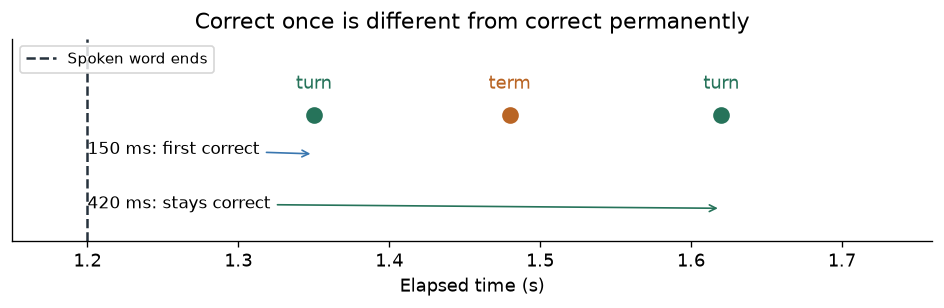

In [16]:
fig, ax = plt.subplots(figsize=(8, 2.7))
for time, text in histories[0][2]:
    color = "#26735a" if text == "turn" else "#b96525"
    ax.plot(time, 1, "o", color=color, ms=9)
    ax.text(time, 1.12, text, ha="center", color=color)
ax.axvline(1.20, color="#26323d", ls="--", label="Spoken word ends")
ax.annotate("150 ms: first correct", (1.35,.82), (1.20,.82),
            arrowprops={"arrowstyle":"->", "color":"#3976af"}, fontsize=10)
ax.annotate("420 ms: stays correct", (1.62,.57), (1.20,.57),
            arrowprops={"arrowstyle":"->", "color":"#26735a"}, fontsize=10)
ax.set(xlim=(1.15,1.76), ylim=(.42,1.35), yticks=[], xlabel="Elapsed time (s)",
       title="Correct once is different from correct permanently")
ax.legend(loc="upper left", fontsize=9); fig.tight_layout(); display(fig); plt.close(fig)